# Vinculum 05 · The signal library (neural-processor)

`neural-processor` turns vinculum's point-in-time data into signals per security: valuation,
profitability, quality, leverage, growth, price and short-interest signals, each with its
formula, inputs and the direction the literature expects. `Processor.panel()` builds a panel
for a universe ranked on each date; `transform`, `neutralize` and `composite` work per date.

1. the catalogue
2. a panel of every signal
3. coverage
4. how the signals relate
5. sector and size neutralization
6. composites
7. a first look at predictive power
8. caveats

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from massive_subspace_stream import Store
from neural_processor import GROUPS, SIGNALS, Processor, catalogue, composite, neutralize
from subspace_probe import style, timed
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(80)
v, massive = Vinculum(), Store()
p = Processor(vinculum=v, store=massive)
NAMES = list(SIGNALS)
START, TOP = "2015-01-01", 1000

## 1 · The catalogue

`direction` is +1 where a higher value has gone with higher future returns in the literature,
-1 where lower has. `source` says how the panel computes the signal: an expression over
fundamentals, a comparison with the values usable a year earlier (growth), daily bars (price) or
FINRA short interest as published.

In [2]:
catalogue().select("name", "group", "formula", "direction", "source", "note")

name,group,formula,direction,source,note
str,str,str,i64,str,str
"""earnings_yield""","""value""","""net income / market cap (inverse P/E)""",1,"""fundamental""",""""""
"""book_to_market""","""value""","""equity / market cap""",1,"""fundamental""",""""""
"""sales_to_price""","""value""","""revenue / market cap""",1,"""fundamental""",""""""
"""cash_flow_yield""","""value""","""operating cash flow / market cap""",1,"""fundamental""",""""""
"""fcf_yield""","""value""","""(operating cash flow - capex) / market cap""",1,"""fundamental""",""""""
"""dividend_yield""","""value""","""dividends paid / market cap""",1,"""fundamental""",""""""
"""shareholder_yield""","""value""","""(dividends + buybacks) / market cap; a missing one counts as 0""",1,"""fundamental""",""""""
"""ebit_to_ev""","""value""","""operating income / EV""",1,"""fundamental""",""""""
"""ebitda_to_ev""","""value""","""(operating income + D&A) / EV""",1,"""fundamental""",""""""


## 2 · A panel of every signal

All signals for the 1,000 largest companies on each month end since 2015. The universe is
ranked on each date from what traded then, so companies that later failed or were acquired
are in while they traded. Price signals use bars up to that day's close; fundamentals the
filings usable that day; short interest the latest report already published.

In [3]:
with timed(f"{len(NAMES)} signals, top {TOP:,}, month ends {START[:4]}-2026"):
    s = p.panel(NAMES, start=START, top=TOP)
print(f"{s.height:,} rows, {s['date'].n_unique()} month ends, {s['security_id'].n_unique():,} securities")
s.filter(pl.col("ticker").is_in(["AAPL", "XOM"]) & (pl.col("date") == s["date"].max())).select(
    "ticker", "sector", "earnings_yield", "roe", "revenue_growth", "momentum_12_1", "beta_12m", "si_pct_float")

48 signals, top 1,000, month ends 2015-2026: 49.02 s
142,000 rows, 142 month ends, 2,329 securities


ticker,sector,earnings_yield,roe,revenue_growth,momentum_12_1,beta_12m,si_pct_float
str,str,f64,f64,f64,f64,f64,f64
"""AAPL""","""Business equipment""",0.025608,1.199126,0.142424,0.231578,0.479799,0.009074
"""XOM""","""Energy""",0.032877,0.097594,-0.011335,0.46017,-0.658621,0.010388


ExxonMobil moved to a new security in July 2026. Its momentum, beta and growth still have a
full history: the library follows vinculum's successor links, so the old security's bars and
filings before the switch count as the new one's.

## 3 · Coverage

Share of the top 1,000 with a value, on the latest month end and through time by group (the
mean over the group's signals).

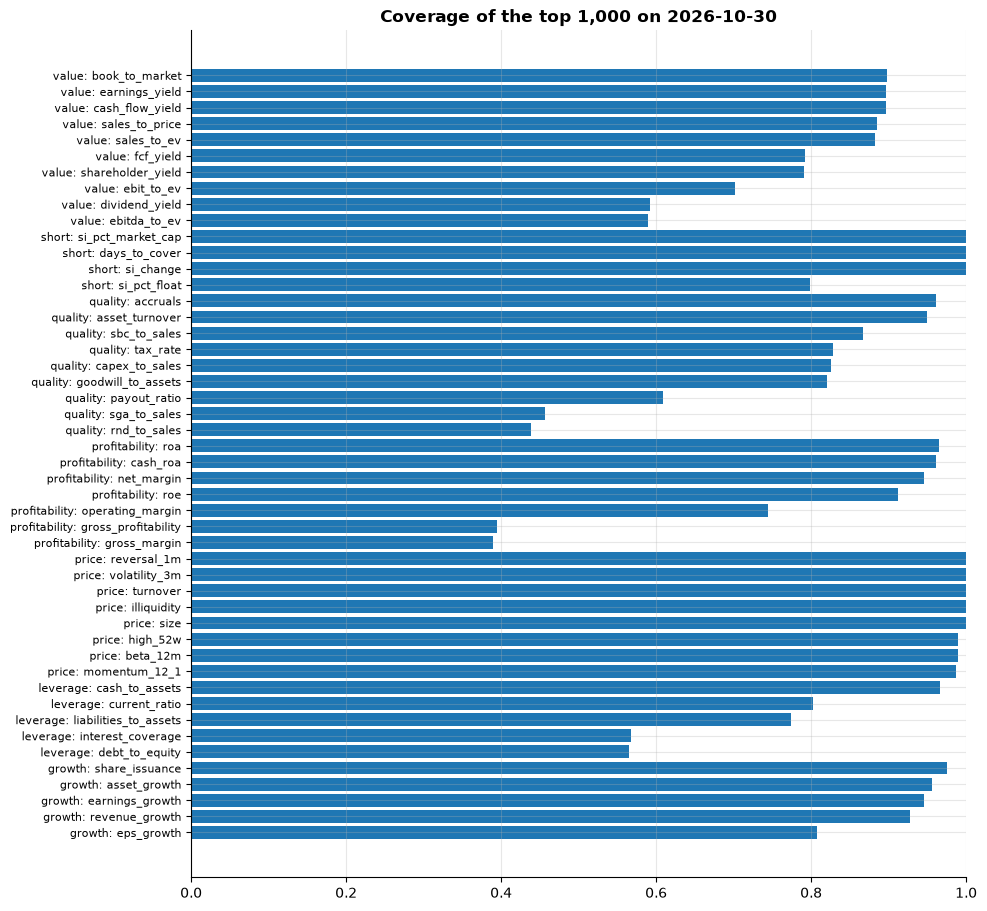

In [4]:
last = s["date"].max()
cur = s.filter(pl.col("date") == last)
cov = pl.DataFrame({"signal": NAMES, "group": [SIGNALS[n].group for n in NAMES],
                    "coverage": [cur[n].is_not_null().mean() for n in NAMES]})
fig, ax = plt.subplots(figsize=(10, 11))
order = cov.sort(["group", "coverage"])
ax.barh(np.arange(order.height), order["coverage"])
ax.set_yticks(np.arange(order.height), [f"{g}: {n}" for g, n in zip(order["group"], order["signal"], strict=True)],
              fontsize=8)
ax.set_xlim(0, 1)
ax.set_title(f"Coverage of the top {TOP:,} on {last}")
plt.show()

In [5]:
yr = s.with_columns(pl.col("date").dt.year().alias("year"))
by_group = (yr.group_by("year").agg([pl.mean_horizontal([pl.col(n).is_not_null().mean() for n in NAMES
                                                         if SIGNALS[n].group == g]).alias(g) for g in GROUPS])
            .sort("year"))
by_group.with_columns(pl.exclude("year").round(2))

year,value,profitability,quality,leverage,growth,price,short
i32,f64,f64,f64,f64,f64,f64,f64
2015,0.85,0.77,0.74,0.74,0.89,0.98,0.0
2016,0.86,0.77,0.75,0.74,0.9,0.98,0.0
2017,0.85,0.77,0.75,0.74,0.9,0.98,0.0
2018,0.82,0.78,0.75,0.74,0.84,0.98,0.96
2019,0.81,0.79,0.77,0.74,0.88,0.98,0.95
2020,0.81,0.8,0.76,0.75,0.9,0.98,0.95
2021,0.8,0.79,0.75,0.76,0.89,0.98,0.95
2022,0.81,0.78,0.77,0.76,0.9,0.99,0.95
2023,0.81,0.79,0.77,0.76,0.93,0.99,0.96


- **Price signals** cover nearly everyone; momentum and beta need a year of trading, so recent
  listings are missing.
- **Fundamental ratios** follow the items (see 01): gross margin and R&D are reported by fewer
  than half of the companies, interest coverage and debt-to-equity by about 60%.
- **Short interest** starts in late 2017 (`si_pct_float` also needs a 10-K public float).
- **Growth** needs a value a year earlier: newly listed companies get none in their first year.

## 4 · How the signals relate

The average monthly rank correlation between signals, each oriented by its direction (so a
positive correlation means two signals pick the same winners). What it shows:

- **Earnings-based value** (earnings yield, EBITDA/EV, FCF yield) is one cluster (0.5-0.8).
  **Book-to-market** stands apart and runs *against* profitability (about -0.5 with gross
  profitability and cash ROA): cheap on book usually means low returns on capital.
- **Profitability** signals move together, and with interest coverage (0.4-0.6).
- **Momentum** is mildly opposed to value (-0.1 to -0.3), which is why the two combine well.
- **Low volatility, low beta and low short interest** pick the same stocks (0.5-0.6), and
  small companies are the most shorted (size vs short interest -0.5).
- **Revenue growth** and low **asset growth** pull in opposite directions (-0.5): fast growers
  invest.

monthly rank correlations: 0.31 s


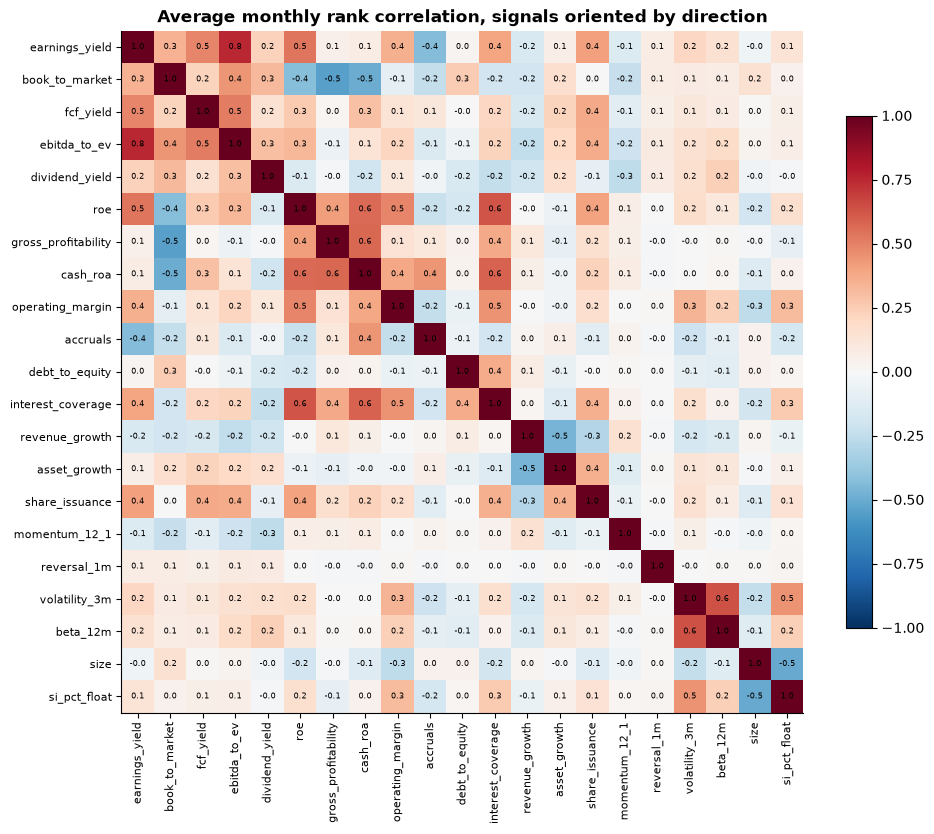

In [6]:
show = ["earnings_yield", "book_to_market", "fcf_yield", "ebitda_to_ev", "dividend_yield",
        "roe", "gross_profitability", "cash_roa", "operating_margin", "accruals",
        "debt_to_equity", "interest_coverage", "revenue_growth", "asset_growth", "share_issuance",
        "momentum_12_1", "reversal_1m", "volatility_3m", "beta_12m", "size", "si_pct_float"]
oriented = s.select("date", *[(pl.col(n) * SIGNALS[n].direction).alias(n) for n in show])
ranked = oriented.with_columns([pl.col(n).rank().over("date") for n in show])
with timed("monthly rank correlations"):
    mats = []
    for _, g in ranked.group_by("date"):
        m = g.select(show).to_pandas().corr(min_periods=100)
        mats.append(m.to_numpy())
corr = np.nanmean(np.stack(mats), axis=0)
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(show)), show, rotation=90, fontsize=8)
ax.set_yticks(range(len(show)), show, fontsize=8)
for (i, j), val in np.ndenumerate(corr):
    ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=6)
ax.grid(False)
fig.colorbar(im, shrink=0.7)
ax.set_title("Average monthly rank correlation, signals oriented by direction")
plt.show()

## 5 · Sector and size neutralization

Raw value signals are partly sector bets: banks and energy look cheap on book-to-market,
software looks expensive. `neutralize(df, cols, ["sector"])` demeans each signal within its
FF12 sector per date; adding `"size"` also removes what log market cap explains.

In [7]:
lastm = s.filter(pl.col("date") == last)
neut = neutralize(lastm, ["book_to_market"], ["sector"]).rename({"book_to_market": "bm_neutral"})
both = lastm.select("security_id", "sector", "book_to_market").join(neut.select("security_id", "bm_neutral"),
                                                                    on="security_id")
(both.group_by("sector").agg(pl.len().alias("companies"), pl.col("book_to_market").median().alias("raw_median"),
                             pl.col("bm_neutral").median().alias("neutral_median"))
 .sort("raw_median", descending=True).with_columns(pl.col(pl.Float64).round(3)))

sector,companies,raw_median,neutral_median
str,u32,f64,f64
null,1,1.01,0.0
"""Energy""",39,0.551,-0.014
"""Finance""",203,0.498,-0.028
"""Telecom""",21,0.47,-0.152
"""Utilities""",56,0.448,0.009
"""Consumer durables""",21,0.356,-0.083
"""Consumer non-durables""",34,0.354,-0.117
"""Chemicals""",23,0.285,-0.086
"""Manufacturing""",104,0.218,-0.039


In [8]:
cols = ["earnings_yield", "book_to_market", "fcf_yield", "roe", "gross_margin", "momentum_12_1", "volatility_3m"]
n2 = neutralize(s.select("date", "security_id", "sector", "issuer_market_cap", *cols), cols, ["sector", "size"])
j = s.select("date", "security_id", *cols).join(n2.select("date", "security_id", *[pl.col(c).alias(f"{c}_n") for c in cols]),
                                                on=["date", "security_id"])
pl.DataFrame({"signal": cols, "corr_raw_vs_neutral": [
    j.group_by("date").agg(pl.corr(c, f"{c}_n", method="spearman").alias("r"))["r"].mean() for c in cols]}).with_columns(
    pl.col("corr_raw_vs_neutral").round(2))

signal,corr_raw_vs_neutral
str,f64
"""earnings_yield""",0.82
"""book_to_market""",0.75
"""fcf_yield""",0.86
"""roe""",0.52
"""gross_margin""",0.78
"""momentum_12_1""",0.88
"""volatility_3m""",0.79


A correlation near 1 means the signal is mostly about the company itself; a low one means much
of it was sector or size. ROE changes most (0.52): banks' leverage and large companies'
profitability explain much of it. Book-to-market (0.75) and volatility (0.79) carry sector and
size too; momentum and FCF yield stay closest to their raw ranks.

## 6 · Composites

`composite(df, weights)` orients each signal by its direction, z-scores it per date (after
winsorizing at 1%/99%) and averages what a row has. Three composites, and the companies that
score best on value and quality together today:

In [9]:
VALUE = ["earnings_yield", "book_to_market", "fcf_yield", "ebitda_to_ev"]
QUALITY = ["roe", "gross_profitability", "cash_roa", "accruals"]
c = composite(s, VALUE, name="value", min_signals=2)
c = composite(c, QUALITY, name="quality", min_signals=2)
c = composite(c, ["momentum_12_1"], name="momentum")
c = composite(c, {"value": 1, "quality": 1}, name="value_quality")
print(c.group_by("date").agg(pl.corr("value", "quality", method="spearman").alias("value_quality"),
                             pl.corr("value", "momentum", method="spearman").alias("value_momentum"),
                             pl.corr("quality", "momentum", method="spearman").alias("quality_momentum"))
      .select(pl.exclude("date").mean().round(2)))
(c.filter(pl.col("date") == last).sort("value_quality", descending=True, nulls_last=True).head(12)
 .select("ticker", "sector", (pl.col("issuer_market_cap") / 1e9).round(0).alias("market_cap_bn"),
         *[pl.col(x).round(2) for x in ["value", "quality", "momentum", "value_quality"]]))

shape: (1, 3)
┌───────────────┬────────────────┬──────────────────┐
│ value_quality ┆ value_momentum ┆ quality_momentum │
│ ---           ┆ ---            ┆ ---              │
│ f64           ┆ f64            ┆ f64              │
╞═══════════════╪════════════════╪══════════════════╡
│ -0.14         ┆ -0.2           ┆ 0.07             │
└───────────────┴────────────────┴──────────────────┘


ticker,sector,market_cap_bn,value,quality,momentum,value_quality
str,str,f64,f64,f64,f64,f64
"""OSCR""","""Finance""",9.0,1.11,2.54,1.08,2.49
"""LTM""","""Other""",12.0,1.87,1.34,-0.12,2.19
"""APA""","""Energy""",19.0,1.87,1.22,1.49,2.1
"""PUK""","""Finance""",31.0,1.58,null,-0.62,2.03
"""CHRD""","""Energy""",9.0,2.35,0.64,0.76,1.95
"""LULU""","""Consumer non-durables""",11.0,1.69,1.08,-1.31,1.88
"""PBF""","""Energy""",9.0,3.05,0.53,2.31,1.88
"""EVR""","""Finance""",11.0,0.65,2.01,-0.63,1.87
"""TPR""","""Consumer non-durables""",23.0,0.11,2.53,-0.31,1.83


## 7 · A first look at predictive power

The monthly rank correlation (IC) of each signal, oriented, with the next month's total return.
This is a screen, not a backtest: no costs, no portfolio construction, equal weight on every
stock. Proper tests belong to the planned backtester (`unimatrix-zero`).

month-end total-return closes: 2.69 s


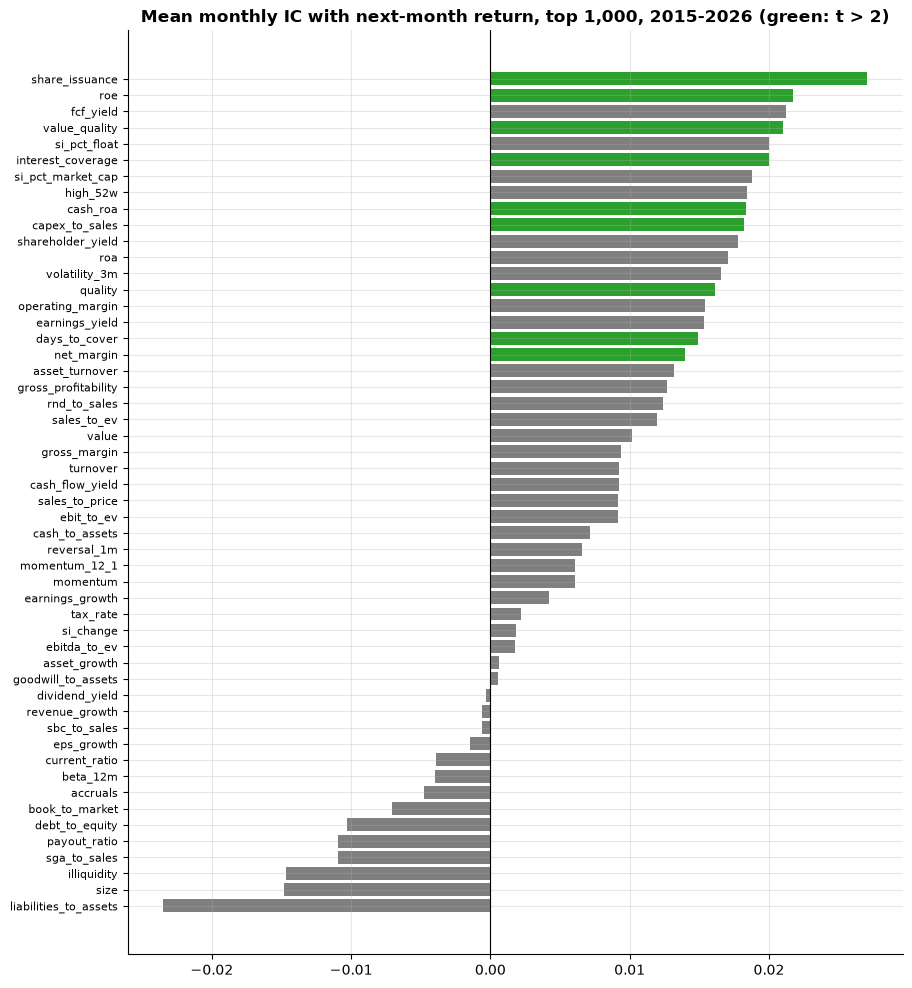

signal,group,months,mean_ic,t_stat
str,str,i64,f64,f64
"""share_issuance""","""growth""",141,0.027,3.057
"""roe""","""profitability""",141,0.022,2.856
"""fcf_yield""","""value""",141,0.021,1.841
"""value_quality""","""composite""",141,0.021,2.333
"""si_pct_float""","""short""",105,0.02,1.727
"""interest_coverage""","""leverage""",141,0.02,2.535
"""si_pct_market_cap""","""short""",105,0.019,1.674
"""high_52w""","""price""",141,0.018,1.123
"""cash_roa""","""profitability""",141,0.018,2.158


In [10]:
month = pl.col("date").dt.truncate("1mo").alias("month")
with timed("month-end total-return closes"):
    px = (massive.bars(None, start=START, adjust="all", lazy=True).filter(pl.col("security_id").is_not_null())
          .group_by("security_id", month).agg(pl.col("close").sort_by("date").last()).collect())
px = px.with_columns((pl.col("month").dt.year() * 12 + pl.col("month").dt.month()).alias("m"))
px = px.join(px.select("security_id", (pl.col("m") - 1).alias("m"), pl.col("close").alias("close_next")),
             on=["security_id", "m"], how="left").with_columns((pl.col("close_next") / pl.col("close") - 1).alias("ret_next"))
panel = c.with_columns(month).join(px.select("security_id", "month", "ret_next"), on=["security_id", "month"])
ics = []
for n in [*NAMES, "value", "quality", "momentum", "value_quality"]:
    sign = SIGNALS[n].direction if n in SIGNALS else 1
    g = (panel.filter(pl.col(n).is_not_null() & pl.col("ret_next").is_not_null())
         .with_columns((pl.col(n) * sign).alias("__x"))
         .group_by("date").agg(pl.corr("__x", "ret_next", method="spearman").alias("ic"), pl.len().alias("n"))
         .filter(pl.col("n") >= 100))
    if g.height:
        ics.append({"signal": n, "group": SIGNALS[n].group if n in SIGNALS else "composite", "months": g.height,
                    "mean_ic": g["ic"].mean(), "t_stat": g["ic"].mean() / g["ic"].std() * np.sqrt(g.height)})
ic = pl.DataFrame(ics).sort("mean_ic", descending=True)
fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(np.arange(ic.height), ic["mean_ic"], color=["tab:green" if t > 2 else "tab:grey" for t in ic["t_stat"]])
ax.set_yticks(np.arange(ic.height), ic["signal"], fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"Mean monthly IC with next-month return, top {TOP:,}, {START[:4]}-2026 (green: t > 2)")
plt.show()
ic.with_columns(pl.col(pl.Float64).round(3)).head(15)

## 8 · Caveats

- **Directions are conventions** from published studies, mostly on older US data. The IC
  screen above shows that several did not hold in large caps since 2015. `note` in the
  catalogue flags the ones with mixed evidence.
- **USD reporters only** for anything over market cap or EV; ratios within a company work for
  every reporting currency.
- **Sector is today's SIC code** (FF12), not point in time.
- **Growth across a split or reorganization**: EPS and share counts are put on one share basis
  with the security's splits; a split shortly after a reorganization is not.
- **Speed**: the panel is computed on request; every signal for the top 1,000 over eleven
  years takes a few minutes, mostly daily bars for the price signals. Ask only for the signals
  a study needs.